# CV Project 1 — Bieu dien anh mau, loc tin hieu va bien doi hinh hoc

This notebook runs all three parts of the assignment end-to-end and displays the results inline:

1. **Part 1** — Color/grayscale representation and color channels
2. **Part 2** — Low-pass and high-pass spatial filtering
3. **Part 3** — Geometric transformations (translation/rotation/scaling, affine, projective)

It is meant to be run either locally (Jupyter) or in Google Colab. Full, reusable source code lives in `src/` (`utils.py`, `part1_color_channels.py`, `part2_filtering.py`, `part3_transformations.py`); this notebook imports and calls it rather than duplicating logic, and only the core snippets are reproduced inline for the report.

## Setup

If running in **Google Colab**, uncomment and run the `git clone` cell below first (replace the URL with this project's own repository link once pushed to GitHub/GitLab). If running **locally** from `notebooks/`, the `sys.path` line below already finds `../src`.

In [1]:
# Colab only: clone the repo so src/ is available, then cd into it.
# !git clone <YOUR_REPO_URL> repo && %cd repo
# !pip install -q -r requirements.txt

import os, sys
SRC_DIR = os.path.abspath(os.path.join("..", "src"))
if SRC_DIR not in sys.path:
    sys.path.insert(0, SRC_DIR)

import numpy as np
import matplotlib.pyplot as plt
import cv2

from utils import load_sample_images, to_gray3, add_gaussian_noise
import part1_color_channels as p1
import part2_filtering as p2
import part3_transformations as p3

images = load_sample_images()
print(list(images.keys()))

['astronaut', 'checkerboard', 'coins', 'camera']


**Note on images used.** Instead of arbitrary downloaded photos (whose licensing/consent status is often unclear), this project uses the standard `scikit-image` sample images (`astronaut`, `checkerboard`, `coins`, `camera`), which are public-domain / redistributable test images bundled with the library and commonly used in the CV literature. This satisfies the assignment's requirement (*"anh, tai lieu su dung can tuan thu cac quy dinh chung cua phap luat va nha truong"*) and makes the notebook fully reproducible without external downloads. You may freely swap in your own photos by editing `load_sample_images()` in `src/utils.py`.

---
## Part 1 — Color image representation and color channels

**Grayscale conversion (luminosity method):**
$$ Y = 0.299\,R + 0.587\,G + 0.114\,B $$
The weights follow human luminance perception (most sensitive to green, least to blue) rather than a flat average of the three channels.

**Key idea:** grayscale conversion is a lossy, many-to-one projection (3 channels -> 1). Splitting R/G/B and recombining them is lossless (identical to the original), but going gray -> color cannot recover the original chrominance -- the best you can do is replicate the single value into R=G=B.

max |manual - cv2| = 1


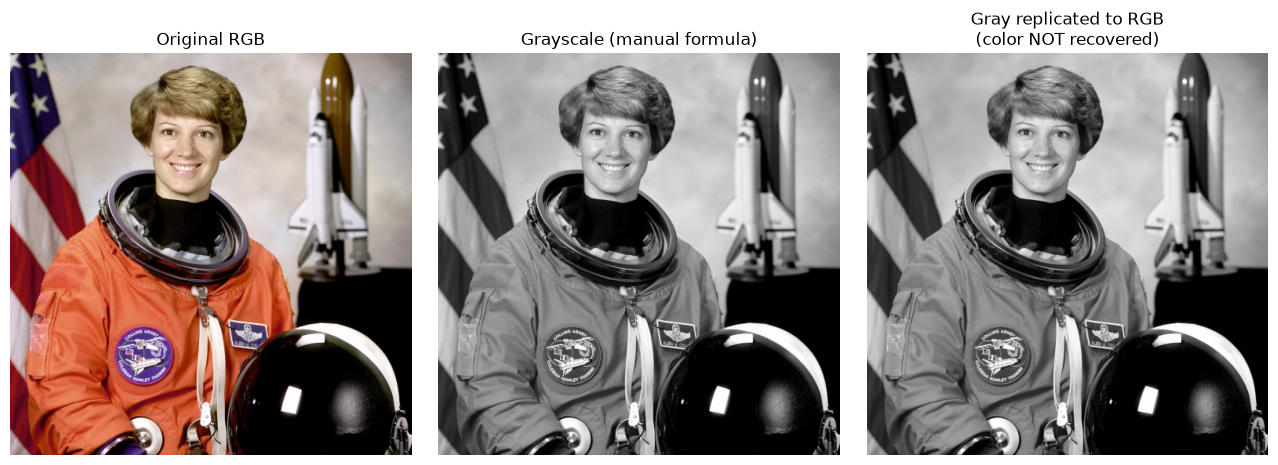

In [2]:
img = images["astronaut"]

gray_manual = p1.rgb_to_gray_manual(img)
gray_cv2 = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
print("max |manual - cv2| =", int(np.max(np.abs(gray_manual.astype(int) - gray_cv2.astype(int)))))

gray_back_to_rgb = p1.gray_to_rgb_replicated(gray_manual)

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
for ax, im, t in zip(axes, [img, to_gray3(gray_manual), gray_back_to_rgb],
                      ["Original RGB", "Grayscale (manual formula)", "Gray replicated to RGB\n(color NOT recovered)"]):
    ax.imshow(im); ax.set_title(t); ax.axis("off")
plt.tight_layout(); plt.show()

Reconstruction identical to original: True


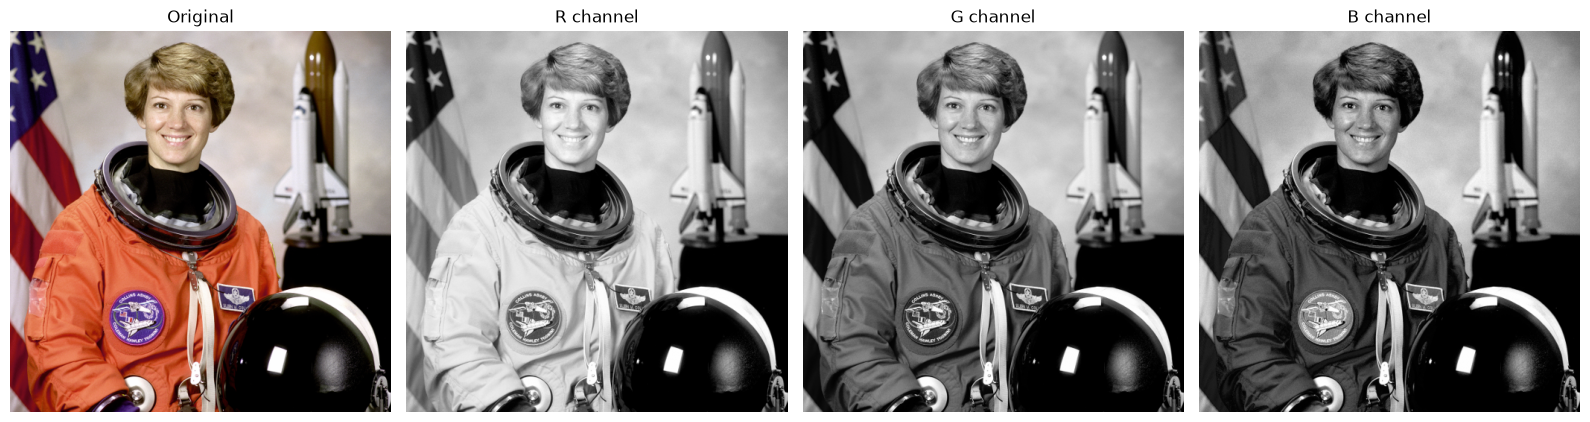

In [3]:
r, g, b = p1.split_channels(img)
reconstructed = p1.reconstruct_from_channels(r, g, b)
print("Reconstruction identical to original:", np.array_equal(reconstructed, img))

fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, im, t in zip(axes, [img, r, g, b], ["Original", "R channel", "G channel", "B channel"]):
    ax.imshow(im, cmap=("gray" if im.ndim == 2 else None)); ax.set_title(t); ax.axis("off")
plt.tight_layout(); plt.show()

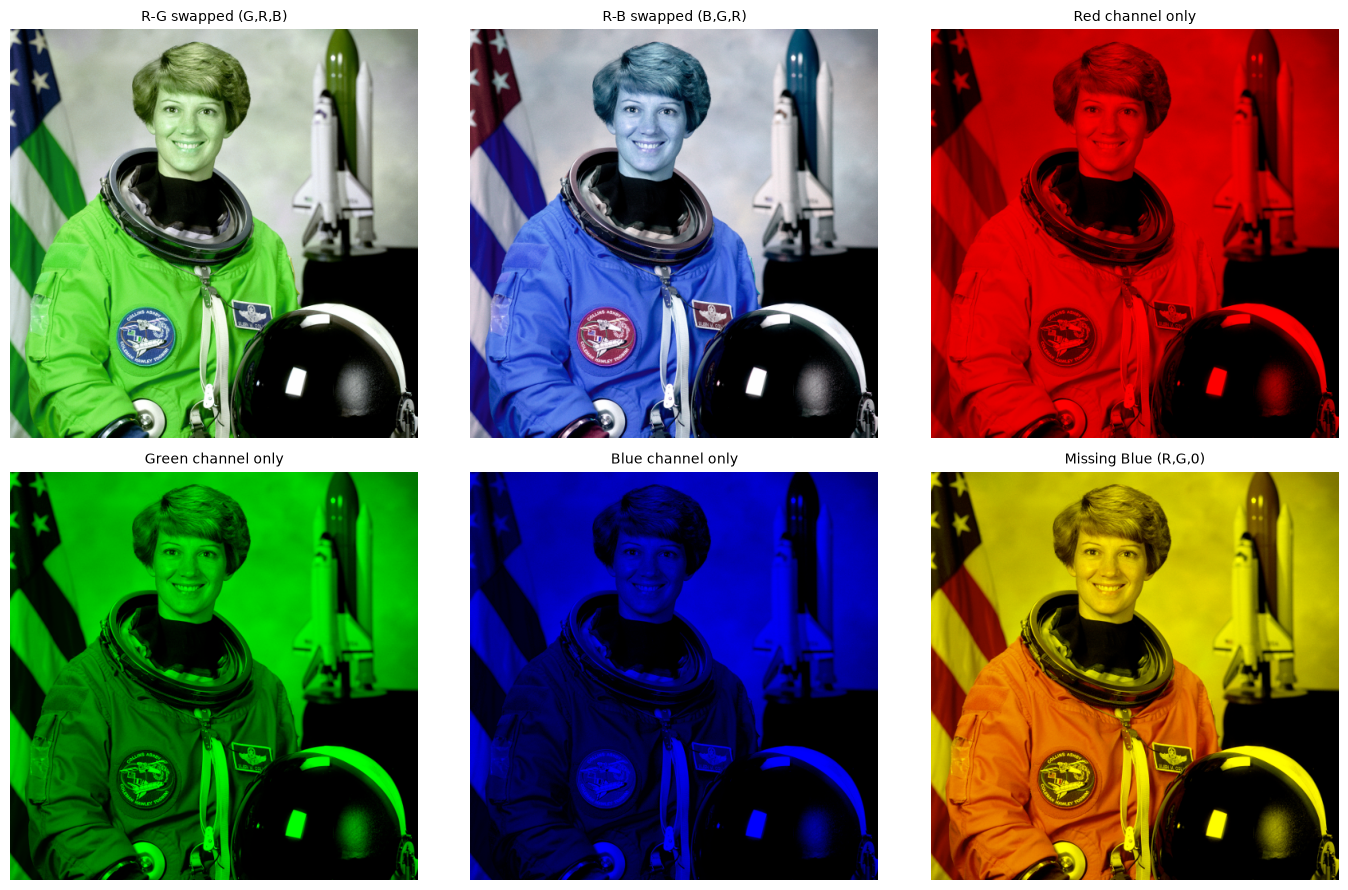

In [4]:
variants = p1.make_swapped_variants(img)
fig, axes = plt.subplots(2, 3, figsize=(14, 9))
for ax, (name, im) in zip(axes.ravel(), variants.items()):
    ax.imshow(im); ax.set_title(name, fontsize=10); ax.axis("off")
plt.tight_layout(); plt.show()

**Nhan xet (observations to expand on in the report):** the R/G/B channel planes, viewed as grayscale, show that each channel captures different scene information depending on the color of the object at that pixel (e.g. the orange spacesuit is bright in R, darker in B). Swapping R<->B visibly shifts warm tones to cool tones because it changes which physical wavelength band is displayed through which display primary; zeroing a channel removes all information that channel alone carried and cannot be recovered from the other two.

---
## Part 2 — Low-pass and high-pass filtering

**Convolution:** $ g(x,y) = \sum_{i,j} f(x-i, y-j)\,k(i,j) $

- **Low-pass** (mean, Gaussian): averages neighboring pixels -> smooths noise but blurs edges. Gaussian weights the center more than the mean filter, so it blurs slightly less for the same kernel size.
- **High-pass** (Laplacian, Sobel, custom sharpen): responds to *changes* in intensity -> highlights edges/detail but amplifies noise.

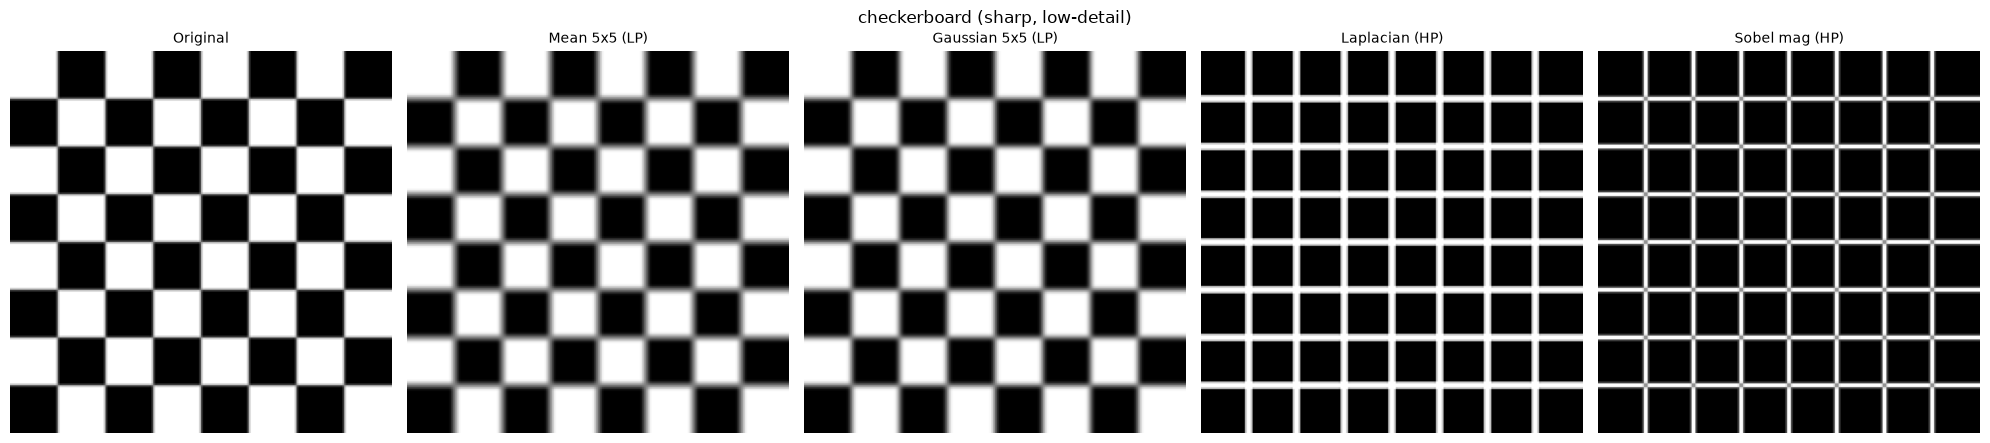

checkerboard (sharp, low-detail): noise proxy original=44.70  mean-filtered=28.51  gaussian-filtered=31.44


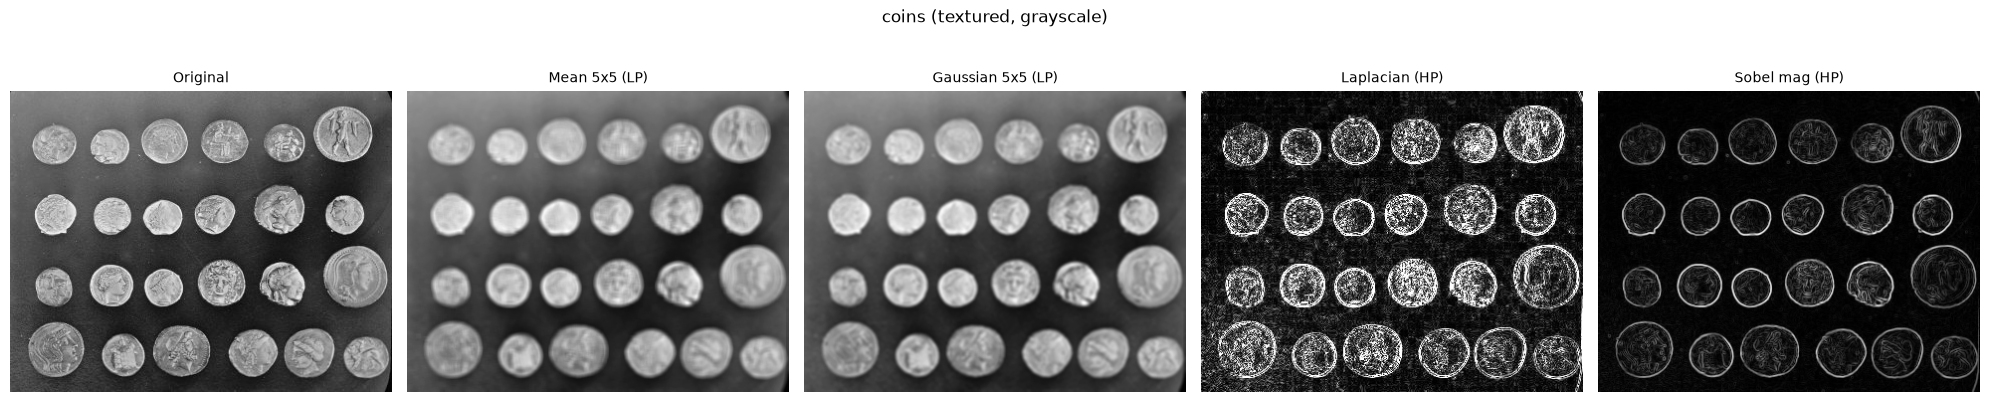

coins (textured, grayscale): noise proxy original=20.19  mean-filtered=9.97  gaussian-filtered=11.28


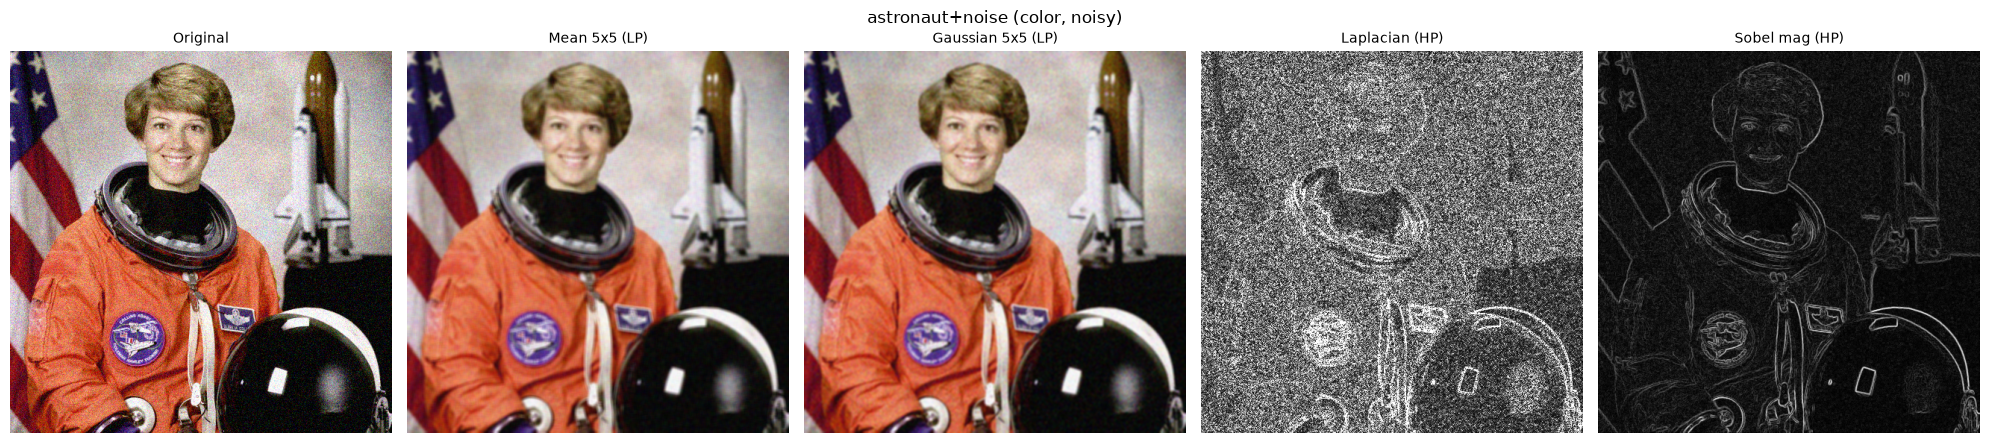

astronaut+noise (color, noisy): noise proxy original=23.19  mean-filtered=10.47  gaussian-filtered=11.66


In [5]:
test_cases = {
    "checkerboard (sharp, low-detail)": images["checkerboard"],
    "coins (textured, grayscale)": images["coins"],
    "astronaut+noise (color, noisy)": add_gaussian_noise(images["astronaut"], sigma=25),
}

for name, im in test_cases.items():
    gray = p2.to_gray(im)
    mean5 = p2.mean_filter(im, 5)
    gauss5 = p2.gaussian_filter(im, 5, 1.5)
    lap = p2.laplacian_filter(gray)
    sob = p2.sobel_filter(gray)
    sharp = p2.custom_sharpen_filter(im)

    fig, axes = plt.subplots(1, 5, figsize=(20, 4.5))
    for ax, im2, t in zip(axes, [im, mean5, gauss5, lap, sob],
                           ["Original", "Mean 5x5 (LP)", "Gaussian 5x5 (LP)", "Laplacian (HP)", "Sobel mag (HP)"]):
        ax.imshow(im2, cmap=("gray" if im2.ndim == 2 else None)); ax.set_title(t, fontsize=10); ax.axis("off")
    fig.suptitle(name)
    plt.tight_layout(); plt.show()

    print(f"{name}: noise proxy original={p2.noise_std(im):.2f}  "
          f"mean-filtered={p2.noise_std(mean5):.2f}  gaussian-filtered={p2.noise_std(gauss5):.2f}")

**Nhan xet:** the noise proxy (std-dev of the high-frequency residual) drops by roughly half after mean/Gaussian filtering on every test image, confirming the low-pass smoothing effect; the drop is similar in magnitude for the clean checkerboard, the textured coins, and the synthetically noised astronaut, but the *visible cost* differs -- the checkerboard's sharp edges get visibly blurred/rounded, while coins (already soft-edged/textured) show comparatively less perceptual quality loss. High-pass filters (Laplacian/Sobel) suppress flat regions to near-black and light up in proportion to local contrast, so they respond strongly to true edges *and* to noise grain equally -- this is why high-pass output on the noisy astronaut looks grainy rather than clean-edged.

---
## Part 3 — Geometric transformations

**Affine transform** (6 DoF, 2x3 matrix): $ \begin{bmatrix}x'\\y'\end{bmatrix} = A \begin{bmatrix}x\\y\end{bmatrix} + t $ — preserves parallelism and ratios of distances along a line.

**Projective / homography** (8 DoF, 3x3 matrix, homogeneous coords): $ \begin{bmatrix}x'\\y'\\w'\end{bmatrix} = H \begin{bmatrix}x\\y\\1\end{bmatrix},\quad (x_{img}, y_{img}) = (x'/w', y'/w') $ — the extra row lets it model perspective (vanishing points); parallel lines can converge.

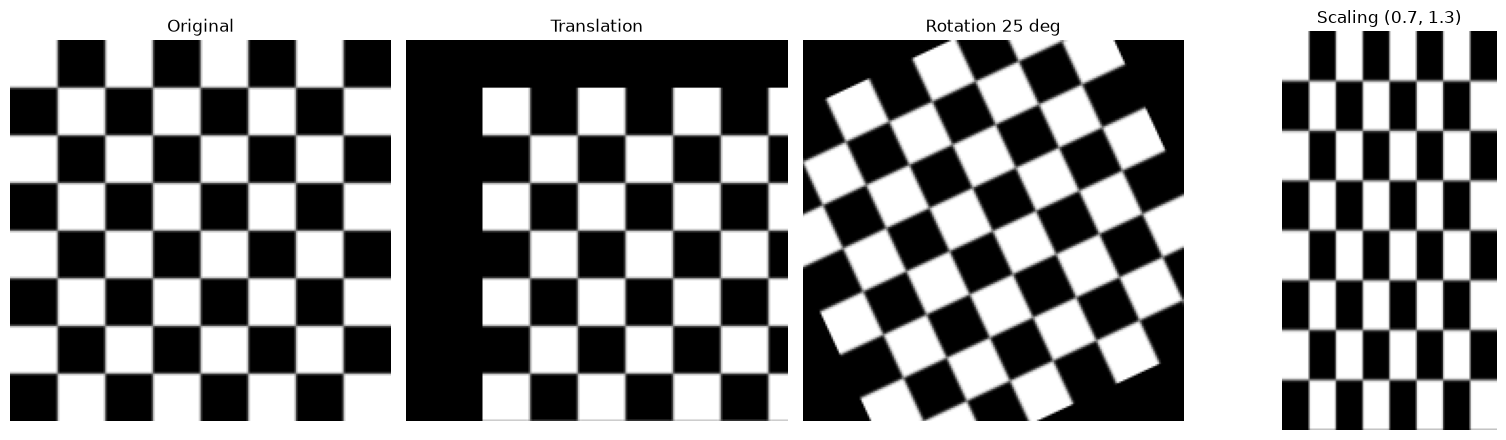

In [6]:
board = to_gray3(images["checkerboard"])

trans = p3.translate(board, tx=40, ty=25)
rot = p3.rotate(board, angle_deg=25)
scl = p3.scale_image(board, fx=0.7, fy=1.3)

fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, im, t in zip(axes, [board, trans, rot, scl],
                      ["Original", "Translation", "Rotation 25 deg", "Scaling (0.7, 1.3)"]):
    ax.imshow(im); ax.set_title(t); ax.axis("off")
plt.tight_layout(); plt.show()

Affine matrix:
 [[ 0.90452261  0.15075377  0.        ]
 [-0.10050251  0.8040201  30.        ]]
Homography matrix:
 [[ 4.42211055e-01 -2.72194305e-01  5.60000000e+01]
 [ 0.00000000e+00  4.01172529e-01  1.00000000e+01]
 [-0.00000000e+00 -2.72194305e-03  1.00000000e+00]]


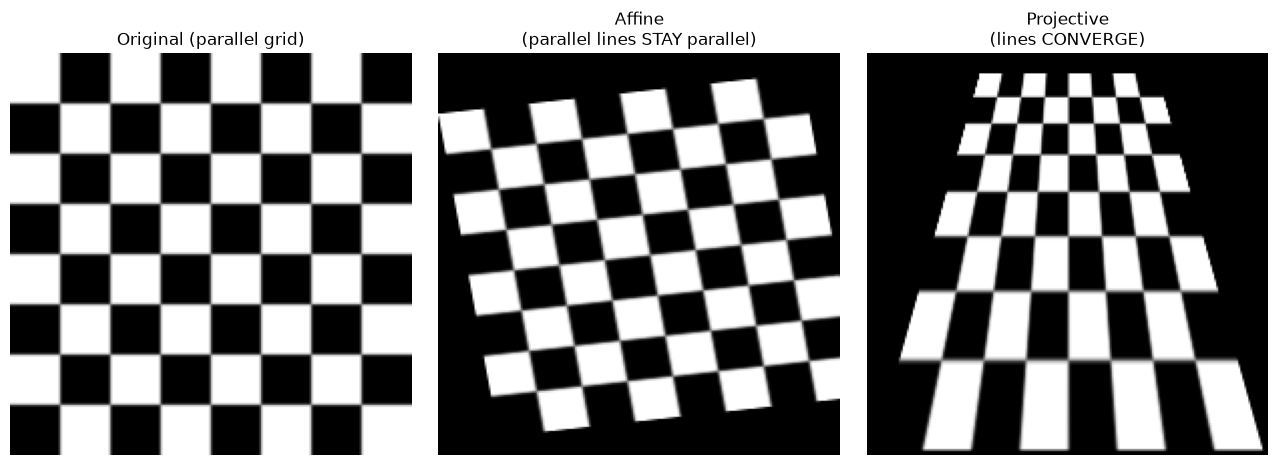

In [7]:
aff, aff_M = p3.affine_transform(board)
proj, proj_M = p3.projective_transform(board)
print("Affine matrix:\n", aff_M)
print("Homography matrix:\n", proj_M)

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
for ax, im, t in zip(axes, [board, aff, proj],
                      ["Original (parallel grid)", "Affine\n(parallel lines STAY parallel)", "Projective\n(lines CONVERGE)"]):
    ax.imshow(im); ax.set_title(t); ax.axis("off")
plt.tight_layout(); plt.show()

**Nhan xet:** on the checkerboard, the affine result is a sheared parallelogram grid -- every pair of lines that was parallel in the original (the horizontal and vertical grid lines) remains parallel after the transform. The projective result instead produces a 'road receding into the distance' look: the originally-vertical lines now converge toward a vanishing point above the image. This is the defining practical difference: **affine models transforms where the camera/scene stays fronto-parallel (pure in-plane motion, shear, scale)**, while **projective/homography models a true change of viewpoint or a planar surface viewed at an angle** (e.g. correcting a photographed document taken at an angle). Affine is fully determined by 3 point correspondences (6 unknowns); projective needs 4 (8 unknowns, up to scale) because of the extra perspective division.

---
## Summary

- Part 1 demonstrated that RGB -> gray is a lossy weighted projection, while splitting/recombining R,G,B is lossless; channel swapping/removal directly and predictably changes the perceived color.
- Part 2 showed low-pass filters trade detail/edge sharpness for noise reduction, and high-pass filters trade noise immunity for edge/detail sensitivity -- the right choice depends on whether the goal is denoising or feature/edge extraction.
- Part 3 showed affine transformations preserve parallelism (in-plane transforms), while projective transformations model perspective and can bend parallel lines toward vanishing points (viewpoint change / planar rectification).

All figures generated by this notebook are also saved under `outputs/part1`, `outputs/part2`, `outputs/part3` by running the corresponding scripts in `src/` directly (`python src/part1_color_channels.py`, etc.), for direct embedding in the PDF report.